# EDA 3 — Experimento 2.4: falsación de H3 y calibradores del nivel de ciudad

**Qué decide este notebook.** Cuatro piezas que cierran la semana 2 del plan (`PLAN_15_OCT.md` §4, fila 2.4):

| Parte | Pregunta | Fuente |
|---|---|---|
| **(a)** | **H3**: ¿la distribución territorial de la brecha de robo a conductor se repite entre 2019 y jul-2021 → abr-2022 más que el azar? | `resultados/11_` (no se recalcula la brecha) |
| **(b)** | Concordancia secundaria: ¿la brecha por alcaldía va en la misma dirección que el % que se siente inseguro en la ENSU? | `resultados/11_` + ENSU 2026 T1–T2 |
| **(c)** | Calibrador definitivo del nivel de ciudad de violencia familiar: no denuncia en la ENDIREH 2021, familia o pareja, con Rao-Wu | ENDIREH 2021 (microdatos) |
| **(d)** | Cota de ENVIPE para robo en calle y transporte, con IC, CV y n | ENVIPE 2025 (microdatos) |

**Reglas que ya estaban fijadas antes de ejecutar esto** (no se tocan aquí):
- La agregación de H3 se fijó el **5 de oct** (`PLAN_15_OCT.md` §3.1), antes de calcular cualquier correlación entre ventanas: **grupos de AGEB contiguos dentro de la misma alcaldía con ≥ 12 carpetas en cada ventana**. Dieron 77 grupos, de los que **76 cumplen** el umbral. H3 se prueba con esos 76 y con nada más.
- La prueba es **Spearman de la brecha del grupo entre las dos ventanas**, contra una **nula de permutación de unidades** (semilla 2026, 1,000 permutaciones), con **IC 95% de la ρ por bootstrap de unidades** (el mismo `estabilidad()` que usó la prueba de S4 en `build_eda2.py` §8.5, para que las dos ρ sean comparables).
- **Qué refuta H3:** que la ρ observada no supere el percentil 95 de la nula. Con n = 76 ese percentil ronda **ρ ≈ 0.19** (1.645/√75), así que solo una estabilidad moderada se distingue del azar: si sale por debajo, el resultado se reporta como **posible falta de potencia** y no solo como ausencia de señal (riesgo registrado en §7).
- Aquí **no se recalcula la brecha, ni los grupos, ni los conteos**: se leen de `resultados/11_ageb_brecha_por_delito.csv` (experimento 2.1). Los 2 AGEB sin polígono y los 42 de Milpa Alta quedan fuera, igual que en el 2.1.

**Supuestos que aplican a este notebook** (formato del criterio transversal — *por qué es válido aquí*, no *qué se hizo*):
- **S4 (estabilidad territorial).** Uso 2019 y jul-2021 → abr-2022 como una sola ventana para describir el territorio, asumiendo que el *orden* de la brecha entre unidades es estable entre ambas. **La parte (a) es justamente la prueba de ese supuesto en el par mejor mapeado.** Si no se cumpliera, el resultado habría que reportarlo por ventana y pedir 2023–24 por PNT.
- **S2 (universo del calibrador).** Uso la no denuncia de la ENDIREH (mujeres de 15+, familia o pareja) como cota del nivel de ciudad de la carpeta "VIOLENCIA FAMILIAR", asumiendo que hombres y menores de 15 —entre **30% y 39%** de las víctimas FGJ de 2021— no denuncian muy distinto, y que el combinado *familia o pareja* corresponde a lo que la FGJ junta en una sola carpeta. Si no fuera así, la calibración se restringiría a las víctimas FGJ mujeres de 15+ (el archivo de víctimas cuenta víctimas, no carpetas) y el resto se declararía fuera de alcance.
- **S3 (desfase).** Uso el calibrador para toda la ventana 911 asumiendo que la propensión a denunciar durante el confinamiento no fue muy distinta de la de 2019 y 2021–22. La ENDIREH mide **oct-2020 → nov-2021**, dentro del hueco COVID: solo jul–nov 2021 se traslapa. Si la propensión cambió (la FGJ subió 1.34× entre ventanas), la cota vale solo para 2021–22; contrastar con la ENDIREH 2016 queda como trabajo futuro.
- **S6 (la brecha no es el subregistro).** Todo lo que sigue **acota y aproxima**: la brecha ordena territorios y el calibrador acota el nivel de ciudad. Ninguna cifra de aquí estima el subregistro real, que no es conocible.

**Lenguaje:** acotar, aproximar, brecha relativa, rango. Nunca *estimar el subregistro*.

In [1]:
import glob, io, re, unicodedata, warnings, zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50, "display.width", 200, "display.max_colwidth", 120, "display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

ROOT = Path.cwd() if (Path.cwd() / "carpetas-datos").exists() else Path.cwd().parent
OUT = ROOT / "resultados"; OUT.mkdir(exist_ok=True)
ENVIPE = ROOT / "conjunto_de_datos_envipe_2025_csv"
SEMILLA, B = 2026, 1000      # mismas que en build_eda.py y build_eda2.py
RNG = np.random.default_rng(SEMILLA)
UMBRAL = 12                  # fijado el 5 oct (PLAN §3.1): CV de Poisson 1/√12 = 28.9% ≤ 30%
VENT = ["2019", "2021-22"]

def norm(s):
    # Normaliza nombres (sin acentos, mayúsculas, espacios simples) para joins entre fuentes
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return re.sub(r"\s+", " ", s.upper().strip())

ALC_FIX = {"CUAJIMALPA": "CUAJIMALPA DE MORELOS", "MAGDALENA CONTRERAS": "LA MAGDALENA CONTRERAS"}
def norm_alc(s):
    s = norm(s)
    return ALC_FIX.get(s, s)

filas = []   # se va llenando con las filas de resultados/14_
def anota(parte, descripcion, unidad, n_muestral, numerador, estimador, valor, ic95_inf=np.nan, ic95_sup=np.nan,
          p95_nula=np.nan, p_perm=np.nan, cv=np.nan, lectura=""):
    filas.append(dict(parte=parte, descripcion=descripcion, unidad=unidad, n_muestral=n_muestral, numerador=numerador,
                      estimador=estimador, valor=valor, ic95_inf=ic95_inf, ic95_sup=ic95_sup, p95_nula=p95_nula,
                      p_perm=p_perm, cv=cv, lectura=lectura))
print(ROOT)

/Users/emilianosandoval/Documents/code/caso_titulacion


## 1. Parte (a) — H3: estabilidad territorial de la brecha de robo a conductor

Es la pieza P1 del experimento. El par "Robo – Automovilista" ↔ "Robo a pasajero/conductor c/v" es el **único del catálogo con confianza alta** (parcial AGEB 0.42, perfil horario 0.93, tendencia 0.48× vs 0.47×), así que es donde el método tiene que funcionar si funciona en algún lado. Contra la cota de ENVIPE no hay forma honesta de falsarlo (§3.1 y parte (d)); la falsación disponible es la estabilidad.

### 1.1 Las unidades: los 76 grupos fijados el 5 de octubre

Se leen de `11_`, no se reconstruyen. Comprobaciones antes de correlacionar: que sean 76, que la cobertura de eventos sea la registrada en el 2.1 y que ningún grupo quede sin brecha en alguna ventana.

In [2]:
br = pd.read_csv(OUT / "11_ageb_brecha_por_delito.csv", dtype={"ageb": str, "grupo_h3": str})
rc = br[br.delito == "robo_conductor"].copy()
cumple = rc.grupo_cumple_umbral.eq(True)
print(f"Filas de robo a conductor: {len(rc):,} | AGEB con grupo: {rc[rc.grupo_h3.notna()].ageb.nunique():,} | "
      f"AGEB en grupos que cumplen: {rc[cumple].ageb.nunique():,} de {rc.ageb.nunique():,}")

GR = (rc[cumple].groupby(["ventana", "grupo_h3"])
      [["grupo_n_ageb", "grupo_llamadas", "grupo_carpetas", "grupo_brecha", "grupo_brecha_ic95_inf", "grupo_brecha_ic95_sup"]]
      .first())
H3 = GR.grupo_brecha.unstack("ventana")[VENT]
assert len(H3) == 76 and H3.notna().all().all(), "las unidades de H3 no son los 76 grupos completos del 2.1"
print(f"\nGrupos que entran a H3: {len(H3)} | alcaldías representadas: {rc[cumple].alcaldia.nunique()}")
display(GR.groupby("ventana")[["grupo_n_ageb", "grupo_carpetas", "grupo_llamadas", "grupo_brecha"]].describe(percentiles=[.1, .5, .9]).T)
print("Cobertura de eventos dentro de los 76 grupos (sobre los geolocalizados del par):")
display(pd.DataFrame({w: {"llamadas": rc[cumple & rc.ventana.eq(w)].llamadas.sum() / rc[rc.ventana.eq(w)].llamadas.sum(),
                          "carpetas": rc[cumple & rc.ventana.eq(w)].carpetas.sum() / rc[rc.ventana.eq(w)].carpetas.sum()}
                      for w in VENT}).T)

Filas de robo a conductor: 4,866 | AGEB con grupo: 2,431 | AGEB en grupos que cumplen: 2,389 de 2,433

Grupos que entran a H3: 76 | alcaldías representadas: 15


ventana                 2019  2021-22
grupo_n_ageb   count  76.000   76.000
               mean   31.434   31.434
               std    24.638   24.638
               min     2.000    2.000
               10%     7.000    7.000
               50%    22.000   22.000
               90%    69.000   69.000
               max   110.000  110.000
grupo_carpetas count  76.000   76.000
               mean   49.513   19.289
               std    28.807    6.199
               min    13.000   12.000
               10%    21.500   13.000
               50%    43.500   17.500
               90%    89.500   28.000
               max   161.000   35.000
grupo_llamadas count  76.000   76.000
               mean  105.868   42.250
               std    63.680   23.633
               min    15.000    9.000
               10%    39.000   22.500
               50%    90.500   36.500
               90%   183.500   71.500
               max   313.000  161.000
grupo_brecha   count  76.000   76.000
               mean    2.207    2.204
               std     0.795    0.901
               min     0.750    0.692
               10%     1.332    1.056
               50%     2.144    2.179
               90%     3.050    3.293
               max     4.947    5.367

Cobertura de eventos dentro de los 76 grupos (sobre los geolocalizados del par):


,llamadas,carpetas
2019,1.000,0.999
2021-22,0.999,0.999


### 1.2 La prueba: Spearman entre ventanas contra la nula de permutación

`estabilidad()` es la **misma función** que usó la prueba de S4 en `build_eda2.py` §8.5: ρ de Spearman, nula por permutación de unidades (1,000, semilla 2026) con p de una cola = (1 + #{ρ_perm ≥ ρ_obs}) / 1,001, e IC 95% por bootstrap de unidades (1,000, semilla 2026). Usar la misma función es lo que hace comparables la ρ de robo a conductor y la de violencia familiar.

*Supuesto:* uso la permutación de unidades como nula asumiendo que, sin estabilidad real, el orden de la brecha en una ventana no dice nada del orden en la otra. La prueba es de rangos, así que la caída de nivel entre ventanas (911 0.48×, FGJ 0.47×) no la afecta. Si la brecha tuviera patrón de escala mayor que el grupo (autocorrelación), la ρ lo recogería también: separar una cosa de otra es materia del 2.5 (I de Moran), no de esta prueba.

In [3]:
def estabilidad(x, y, B=B, semilla=SEMILLA):
    x, y = np.asarray(x, float), np.asarray(y, float)
    rx, ry = stats.rankdata(x), stats.rankdata(y)
    rho = np.corrcoef(rx, ry)[0, 1]
    rng = np.random.default_rng(semilla)
    nula = np.array([np.corrcoef(rx, rng.permutation(ry))[0, 1] for _ in range(B)])
    rng = np.random.default_rng(semilla)
    boot = []
    for _ in range(B):
        i = rng.integers(0, len(x), len(x))
        boot.append(stats.spearmanr(x[i], y[i])[0])
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return {"n_unidades": len(x), "rho": rho, "ic95_inf": lo, "ic95_sup": hi,
            "p95_nula": np.percentile(nula, 95), "p_perm": (1 + (nula >= rho).sum()) / (B + 1)}, nula

res_h3, nula_h3 = estabilidad(*H3.to_numpy().T)
h3 = pd.DataFrame({"H3: robo a conductor, 76 grupos (regla del 5 oct)": res_h3}).T
h3["n_unidades"] = h3.n_unidades.astype(int)
h3["veredicto"] = np.where(h3.rho > h3.p95_nula, "estable (ρ > p95 de la nula)", "inestable (no se distingue del azar)")
display(h3)
print(f"Potencia: con n = {len(H3)} el percentil 95 teórico de la nula es ρ ≈ {1.645/np.sqrt(len(H3)-1):.3f}; "
      f"el empírico es {res_h3['p95_nula']:.3f}")
print(f"Referencia del 2.1 (no recalculada aquí): violencia familiar, 698 AGEB con ≥ 12 carpetas → ρ = 0.30 "
      f"(IC 0.23–0.37), p95 de la nula 0.065, p = 0.001")

,n_unidades,rho,ic95_inf,ic95_sup,p95_nula,p_perm,veredicto
"H3: robo a conductor, 76 grupos (regla del 5 oct)",76,0.463,0.266,0.626,0.179,0.001,estable (ρ > p95 de la nula)


Potencia: con n = 76 el percentil 95 teórico de la nula es ρ ≈ 0.190; el empírico es 0.179
Referencia del 2.1 (no recalculada aquí): violencia familiar, 698 AGEB con ≥ 12 carpetas → ρ = 0.30 (IC 0.23–0.37), p95 de la nula 0.065, p = 0.001


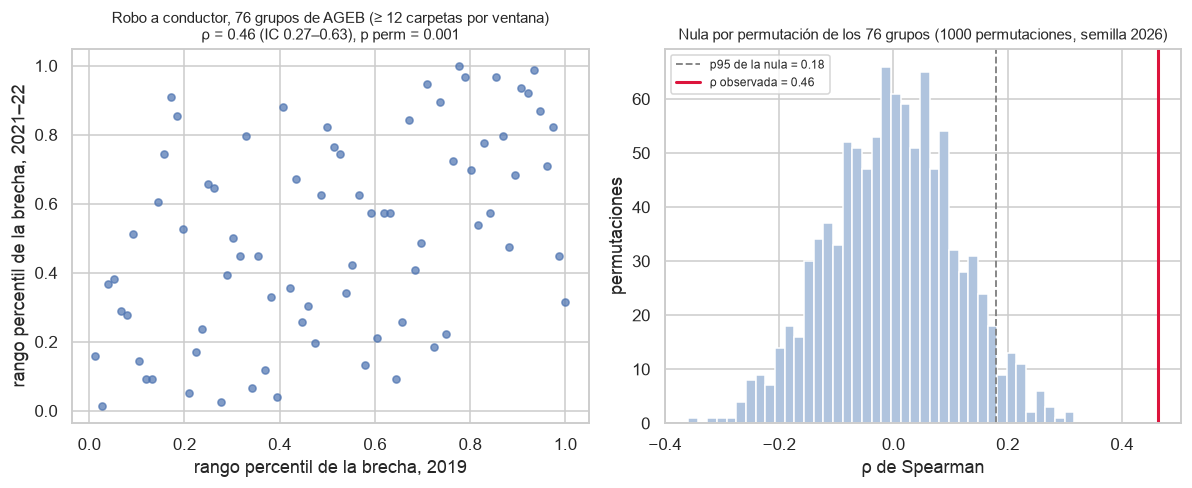

In [4]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.6))
a1.scatter(stats.rankdata(H3["2019"]) / len(H3), stats.rankdata(H3["2021-22"]) / len(H3), s=22, alpha=.7)
a1.set_xlabel("rango percentil de la brecha, 2019"); a1.set_ylabel("rango percentil de la brecha, 2021–22")
a1.set_title(f"Robo a conductor, {len(H3)} grupos de AGEB (≥ {UMBRAL} carpetas por ventana)\n"
             f"ρ = {res_h3['rho']:.2f} (IC {res_h3['ic95_inf']:.2f}–{res_h3['ic95_sup']:.2f}), p perm = {res_h3['p_perm']:.3f}", fontsize=10)
a2.hist(nula_h3, bins=40, color="lightsteelblue", edgecolor="white")
a2.axvline(res_h3["p95_nula"], ls="--", c="grey", lw=1.2, label=f"p95 de la nula = {res_h3['p95_nula']:.2f}")
a2.axvline(res_h3["rho"], c="crimson", lw=2, label=f"ρ observada = {res_h3['rho']:.2f}")
a2.set_xlabel("ρ de Spearman"); a2.set_ylabel("permutaciones")
a2.set_title(f"Nula por permutación de los {len(H3)} grupos ({B} permutaciones, semilla {SEMILLA})", fontsize=10)
a2.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Lectura (H3):** **H3 no se refuta: la brecha de robo a conductor es estable en el territorio.** Entre los 76 grupos fijados el 5 de octubre, la brecha de 2019 y la de jul-2021 → abr-2022 tienen **ρ = 0.46 (IC 95%: 0.27–0.63)**, contra un percentil 95 de la nula de **0.179** (el teórico para n = 76 es 0.190). **p de permutación = 0.001**, el mínimo posible con 1,000 permutaciones: ninguna permutación alcanzó la ρ observada. El veredicto es **estable**.
- **La potencia no fue el problema.** El riesgo registrado en §7 era que con n = 76 solo una estabilidad moderada (ρ ≳ 0.19) superara la nula. La ρ observada queda **2.6× por encima** de ese umbral y su IC 95% completo (0.27–0.63) está arriba, así que el veredicto no depende de estar al filo.
- **Es más estable que violencia familiar** (ρ = 0.30 sobre 698 AGEB, prueba de S4 en el 2.1), que es lo que cabía esperar: la unidad es más gruesa (mediana de 22 AGEB, 43.5 carpetas en 2019 y 17.5 en 2021–22), y agregar promedia ruido de conteo. La ρ observada es, por eso, una **cota inferior** de la estabilidad subyacente: el ruido de Poisson atenúa los rangos en ambas ventanas.
- **Qué grano valida y qué grano no.** H3 dice que la brecha del par mejor mapeado repite su orden **entre grupos de AGEB**, no entre AGEB sueltos: con menos de dos carpetas por AGEB y ventana, eso no se puede probar en robo a conductor y por eso se fijó la agregación antes de correlacionar. El 2.3 ya mostró el costo de ese grano: agregando violencia familiar a esos mismos 76 grupos se pierde ~60% de su variación sub-alcaldía.
- **El nivel se movió, el orden no.** La brecha de ciudad de robo a conductor pasó de 2.14 a 2.19 y la mediana por grupo de 2.14 a 2.18, con 911 y FGJ cayendo casi en la misma proporción (0.48× y 0.47×). La prueba es de rangos, así que eso no la afecta.

**Dónde cae el caso en la tabla de lectura conjunta del §3.1:** robo a conductor **estable** + violencia familiar **estable** = **primera fila**. Es decir: **la brecha lleva señal territorial reproducible y H1 es interpretable.** Hay que decir lo que esto no es: H3 aceptada **no** prueba que la brecha mida subregistro (S6 sigue en pie); prueba que **no es ruido**.

## 2. Parte (b) — concordancia por alcaldía con el % inseguro de la ENSU

**Es concordancia, no prueba.** Con n = 16 alcaldías se necesita |ρ| ≥ 0.50 para p < 0.05, así que no hay grados de libertad para falsar nada: sirve para ver si la brecha va en la dirección de una fuente **independiente** de ambas (encuesta de percepción, no registro). No se usa la razón 911/carpeta total porque contiene al propio par y el resultado sería circular.

*Supuesto:* uso el % que se siente inseguro en la ENSU 2026 como referencia externa asumiendo que el gradiente territorial de la percepción es más estable en el tiempo que su nivel; la brecha es de 2019–22 y la ENSU de 2026, así que la comparación es de **orden entre alcaldías**, no de periodo. Si la percepción se hubiera reordenado entre 2022 y 2026, la concordancia estaría atenuada y no podría leerse como desacuerdo del método.

In [5]:
def read_ensu(zpath):
    z = zipfile.ZipFile(zpath)
    name = [n for n in z.namelist() if re.search(r"ensu_cb_\d+\.csv$", n)][0]
    d = pd.read_csv(io.BytesIO(z.read(name)), dtype=str)
    d["trimestre"] = re.search(r"cb_(\d+)", name).group(1)
    return d

ensu = pd.concat([read_ensu(p) for p in sorted((ROOT / "ENSU").glob("*.zip"))])
ensu = ensu[ensu.CVE_ENT == "09"].copy()
ensu["FAC_SEL"] = ensu.FAC_SEL.astype(float)
ensu["alcaldia"] = ensu.NOM_CD.map(norm_alc)
ins = ensu[ensu.BP1_1.isin(["1", "2"])].groupby("alcaldia").apply(
    lambda d: pd.Series({"n_ensu": len(d), "pct_inseguro": np.average(d.BP1_1.eq("2"), weights=d.FAC_SEL)}))

alc = rc.groupby(["ventana", "alcaldia"])[["llamadas", "carpetas"]].sum()
alc["brecha"] = alc.llamadas / alc.carpetas
cmp_alc = alc.brecha.unstack("ventana")[VENT]
cmp_alc.columns = [f"brecha_{c}" for c in VENT]
tot = rc.groupby("alcaldia")[["llamadas", "carpetas"]].sum()
cmp_alc["brecha_ambas_ventanas"] = tot.llamadas / tot.carpetas
cmp_alc = cmp_alc.join(tot.rename(columns={"llamadas": "llamadas_ambas", "carpetas": "carpetas_ambas"})).join(ins)
display(cmp_alc.sort_values("brecha_ambas_ventanas"))

conc = {}
for c in ["brecha_ambas_ventanas"] + [f"brecha_{w}" for w in VENT]:
    rho, p = stats.spearmanr(cmp_alc[c], cmp_alc.pct_inseguro)
    conc[c] = {"n_alcaldias": len(cmp_alc), "rho": rho, "p_dos_colas": p,
               "rho_minimo_para_p05": 0.50, "concordancia": "en la dirección esperada" if rho > 0 else "en dirección contraria"}
conc = pd.DataFrame(conc).T
display(conc)

,brecha_2019,brecha_2021-22,brecha_ambas_ventanas,llamadas_ambas,carpetas_ambas,n_ensu,pct_inseguro
alcaldia,,,,,,,
AZCAPOTZALCO,1.782,0.991,1.391,327,235,515.000,0.612
MILPA ALTA,1.000,3.000,1.400,7,5,548.000,0.509
MIGUEL HIDALGO,1.701,1.692,1.699,1366,804,519.000,0.378
TLAHUAC,1.545,2.250,1.766,113,64,532.000,0.680
VENUSTIANO CARRANZA,1.626,2.273,1.802,582,323,529.000,0.565
ALVARO OBREGON,1.967,1.868,1.950,1628,835,545.000,0.609
TLALPAN,1.976,1.930,1.960,492,251,522.000,0.539
CUAUHTEMOC,1.953,2.118,2.000,1012,506,519.000,0.530
BENITO JUAREZ,2.244,2.447,2.289,888,388,523.000,0.169


,n_alcaldias,rho,p_dos_colas,rho_minimo_para_p05,concordancia
brecha_ambas_ventanas,16,0.100,0.713,0.500,en la dirección esperada
brecha_2019,16,0.126,0.641,0.500,en la dirección esperada
brecha_2021-22,16,0.106,0.696,0.500,en la dirección esperada


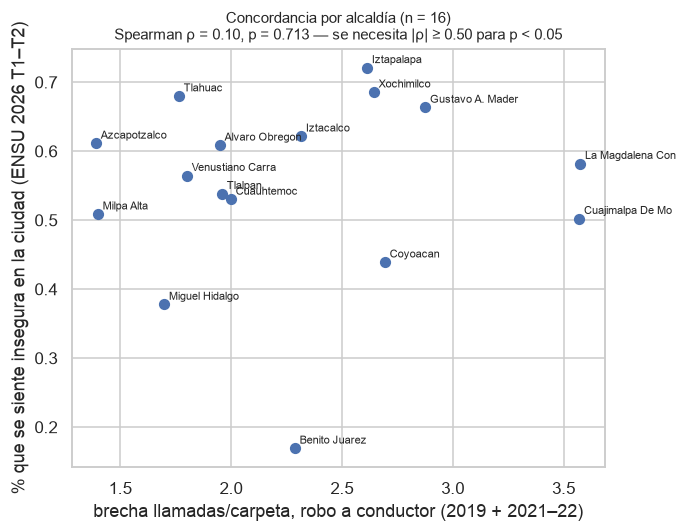

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 5))
ax.scatter(cmp_alc.brecha_ambas_ventanas, cmp_alc.pct_inseguro, s=40)
for i, r in cmp_alc.iterrows():
    ax.annotate(str(i).title()[:16], (r.brecha_ambas_ventanas, r.pct_inseguro), fontsize=7.5,
                xytext=(3, 3), textcoords="offset points")
rho = conc.loc["brecha_ambas_ventanas", "rho"]; p = conc.loc["brecha_ambas_ventanas", "p_dos_colas"]
ax.set_xlabel("brecha llamadas/carpeta, robo a conductor (2019 + 2021–22)")
ax.set_ylabel("% que se siente insegura en la ciudad (ENSU 2026 T1–T2)")
ax.set_title(f"Concordancia por alcaldía (n = {len(cmp_alc)})\nSpearman ρ = {rho:.2f}, p = {p:.3f} — se necesita |ρ| ≥ 0.50 para p < 0.05", fontsize=10)
plt.tight_layout(); plt.show()

**Lectura (concordancia ENSU):** **La concordancia no concluye, y eso se dice así.** ρ = **0.10 (p = 0.71)** con las dos ventanas juntas; 0.13 en 2019 y 0.11 en 2021–22. El signo va en la dirección esperada, pero con n = 16 se necesita |ρ| ≥ 0.50 para p < 0.05: una ρ de 0.1 es indistinguible de cero y **no respalda ni contradice** el método. Toda la carga de la validación queda en la parte (a).
- **Por qué era previsible y no es un golpe al encuadre.** Dos razones, las dos ya medidas en este caso: (i) la ENSU mide percepción de la **ciudad**, y en el EDA 1 la percepción resultó *inversa* a la tasa FGJ (ρ = −0.65), así que no es un termómetro de incidencia; (ii) el 2.3 mostró que la variación de la brecha es **sub-alcaldía** (ICC de alcaldía 0.110), de modo que agregar a 16 unidades destruye justo la señal que el caso encontró.
- **Dos alcaldías lo ilustran:** Benito Juárez tiene brecha alta (2.29) con el 17% de percepción de inseguridad, el mínimo de la ciudad; Milpa Alta aparece con brecha 1.40 construida sobre **5 carpetas y 7 llamadas en total**, puro ruido. Magdalena Contreras (33 carpetas) y Cuajimalpa (42) quedan en el extremo alto con conteos igual de delgados: a grano de alcaldía, la periferia no tiene volumen para este par.
- **Qué se hace con esto:** se reporta como contexto en las slides de respaldo y no se presenta como evidencia a favor. La fuente independiente que sí discrimina a este grano sigue siendo la ENDIREH para el nivel, no la ENSU para el orden.

## 3. Parte (c) — calibrador definitivo del nivel de ciudad: ENDIREH 2021

ENVIPE no mide violencia familiar, así que el nivel de ciudad del caso de aplicación lo acota la **ENDIREH 2021**. Esto es el cálculo definitivo del valor que el plan ya usa (96.6%): el 26 de sep se verificó en un script del scratchpad y aquí queda dentro del entregable, con su diseño muestral y su incertidumbre.

**Universo y definición.** Mujeres de 15+ residentes en CDMX (`CVE_ENT == "09"`, una por vivienda) con violencia **familiar** en los últimos 12 meses (`VFAM`, construida por INEGI sobre "de octubre de 2020 a la fecha") **o** de **pareja** en los últimos 12 meses (`VPAR_12M`). Denuncia = `P11_6_2 == 1` (queja o denuncia ante alguna autoridad por los actos de la familia, mismo periodo de 12 meses) **o** `P14_7_2 == 1` con la **última queja fechada en 2020 o 2021** (`P14_15_1`–`P14_15_4`), porque la pregunta de pareja se refiere a *toda la relación* y sin acotarla mezclaría denuncias viejas con el periodo de referencia.

**Diseño.** Bootstrap Rao-Wu: se remuestrean UPM (`UPM_DIS`) dentro de estratos (`EST_DIS`) con reescalamiento de factores (`FAC_MUJ`), 1,000 réplicas, semilla 2026. INEGI no publica réplicas para la ENDIREH, así que el Rao-Wu es la aproximación propia; en CDMX hay 3 estratos con 2–3 UPM, de modo que **no se puede bajar de grano** (la ENDIREH es representativa por entidad, no por alcaldía).

*Supuesto (precisión):* reporto el CV sobre la **tasa de denuncia** (≈3–4%) y no sobre la no denuncia (≈96%), porque el CV de una proporción cercana a 1 es engañosamente pequeño; con el criterio de INEGI (< 15% alta, 15–30% moderada, > 30% baja) eso deja el calibrador en precisión **moderada**, que es lo que hay que decir en voz alta.

In [7]:
ZE = zipfile.ZipFile(ROOT / "ENDIREH" / "bd_endireh_2021_csv.zip")
def read_endireh(tabla, cols=None):
    # Microdatos en latin-1 con CRLF y sin BOM; los catálogos traen CR dentro de las comillas → .str.strip()
    d = pd.read_csv(io.BytesIO(ZE.read(f"bd_endireh_2021_csv/{tabla}.csv")), dtype=str, encoding="latin-1")
    d.columns = [c.strip() for c in d.columns]
    for c in d.columns:
        d[c] = d[c].str.strip()
    return d[cols] if cols else d

vd = read_endireh("TB_VD", ["ID_PER", "CVE_ENT", "VFAM", "VPAR_12M", "VTOT_12M", "FAC_MUJ", "UPM_DIS", "EST_DIS"])
ANIOS = [f"P14_15_{i}" for i in range(1, 5)]
en = (vd.merge(read_endireh("TB_SEC_XI_2", ["ID_PER", "P11_6_2"]), on="ID_PER", how="left")
        .merge(read_endireh("TB_SEC_XIV", ["ID_PER", "P14_7_2"]), on="ID_PER", how="left")
        .merge(read_endireh("TB_SEC_XIV_2", ["ID_PER"] + ANIOS), on="ID_PER", how="left"))
assert en.ID_PER.is_unique and len(en) == len(vd)
en["FAC_MUJ"] = en.FAC_MUJ.astype(float)
en["den_fam"] = en.P11_6_2.eq("1")
en["den_par"] = en.P14_7_2.eq("1")
en["den_par_reciente"] = en.den_par & en[ANIOS].apply(pd.to_numeric, errors="coerce").isin([2020, 2021]).any(axis=1)

# Control: el código reproduce las cifras publicadas por INEGI
cd = en[en.CVE_ENT == "09"].copy()
print(f"Control nacional — prevalencia de violencia familiar 12 m: {np.average(en.VFAM.eq('1'), weights=en.FAC_MUJ):.3%} "
      f"(INEGI publica 11.4%)")
print(f"Control CDMX — violencia total 12 m: {np.average(cd.VTOT_12M.eq('1'), weights=cd.FAC_MUJ):.3%} (INEGI publica 46.1%)")
print(f"CDMX: {len(cd):,} mujeres de 15+ ({cd.FAC_MUJ.sum():,.0f} expandidas) en {cd.UPM_DIS.nunique()} UPM y {cd.EST_DIS.nunique()} estratos")
print("UPM por estrato en CDMX:", cd.groupby("EST_DIS").UPM_DIS.nunique().to_dict())

Control nacional — prevalencia de violencia familiar 12 m: 11.386% (INEGI publica 11.4%)
Control CDMX — violencia total 12 m: 46.138% (INEGI publica 46.1%)
CDMX: 3,267 mujeres de 15+ (4,075,612 expandidas) en 863 UPM y 8 estratos
UPM por estrato en CDMX: {'0153': 3, '0154': 316, '0155': 386, '0156': 134, '0157': 13, '0158': 2, '0159': 7, '0160': 2}


In [8]:
def rao_wu(df, upms_h, B=B, semilla=SEMILLA):
    # Multiplicadores de factor: remuestreo de UPM dentro de estrato con reescalamiento n_h/(n_h-1)
    rng = np.random.default_rng(semilla)
    mult = {}
    for h, upms in upms_h.items():
        n_h = len(upms)
        m = np.ones((n_h, B)) if n_h < 2 else rng.multinomial(n_h - 1, np.ones(n_h) / n_h, size=B).T * n_h / (n_h - 1)
        for i, u in enumerate(upms):
            mult[u] = m[i]
    return np.vstack([mult[u] for u in df.UPM_DIS])

W_EN = rao_wu(cd, cd.groupby("EST_DIS").UPM_DIS.unique().to_dict()) * cd.FAC_MUJ.to_numpy()[:, None]

def no_denuncia(universo, denuncia, W, fac, etiqueta):
    u = np.asarray(universo); y = np.asarray(denuncia)[u]
    wb = W[u]; w0 = np.asarray(fac)[u]
    tb = (wb * y[:, None]).sum(0) / wb.sum(0)
    tasa = np.average(y, weights=w0)
    se = np.nanstd(tb, ddof=1)
    return {"n_muestral": int(u.sum()), "casos_denuncia": int(y.sum()), "mujeres_expandidas": w0.sum(),
            "tasa_denuncia": tasa, "no_denuncia": 1 - tasa,
            "ic95_inf": 1 - np.nanpercentile(tb, 97.5), "ic95_sup": 1 - np.nanpercentile(tb, 2.5),
            "cv_tasa_denuncia": se / tasa if tasa > 0 else np.inf}

fam, par = cd.VFAM.eq("1"), cd.VPAR_12M.eq("1")
variantes_en = {
    "principal: familia o pareja, 12 m (queja de pareja acotada a 2020–21)": (fam | par, cd.den_fam | cd.den_par_reciente),
    "familia, 12 m (P11_6_2)": (fam, cd.den_fam),
    "pareja, 12 m, queja en cualquier momento de la relación (P14_7_2)": (par, cd.den_par),
    "pareja, 12 m, última queja en 2020–21": (par, cd.den_par_reciente),
    "familia o pareja, sin acotar el periodo de la queja de pareja": (fam | par, cd.den_fam | cd.den_par),
}
endireh = pd.DataFrame({k: no_denuncia(u, d, W_EN, cd.FAC_MUJ, k) for k, (u, d) in variantes_en.items()}).T
endireh["n_muestral"] = endireh.n_muestral.astype(int); endireh["casos_denuncia"] = endireh.casos_denuncia.astype(int)
endireh["precision_INEGI"] = pd.cut(endireh.cv_tasa_denuncia.astype(float), [0, .15, .30, np.inf], labels=["alta", "moderada", "baja"])
display(endireh[["n_muestral", "casos_denuncia", "mujeres_expandidas", "no_denuncia", "ic95_inf", "ic95_sup", "cv_tasa_denuncia", "precision_INEGI"]])

,n_muestral,casos_denuncia,mujeres_expandidas,no_denuncia,ic95_inf,ic95_sup,cv_tasa_denuncia,precision_INEGI
"principal: familia o pareja, 12 m (queja de pareja acotada a 2020–21)",873,34,"1,103,079.000",0.965,0.951,0.978,0.198,moderada
"familia, 12 m (P11_6_2)",465,24,"609,481.000",0.957,0.936,0.976,0.226,moderada
"pareja, 12 m, queja en cualquier momento de la relación (P14_7_2)",594,39,"718,896.000",0.929,0.904,0.952,0.179,moderada
"pareja, 12 m, última queja en 2020–21",594,11,"718,896.000",0.983,0.970,0.993,0.361,baja
"familia o pareja, sin acotar el periodo de la queja de pareja",873,72,"1,103,079.000",0.920,0.899,0.939,0.130,alta


**Lectura (calibrador ENDIREH):** **Calibrador definitivo: 96.5% de no denuncia (IC 95%: 95.1–97.8%).** Mujeres de 15+ en CDMX con violencia familiar o de pareja en los últimos 12 meses: **34 denuncias de 873 mujeres** (1.1 millones expandidas); CV de la tasa de denuncia (3.5%) = **19.8% → precisión moderada** según INEGI. El código reproduce los controles publicados: prevalencia nacional de violencia familiar 12 m **11.386%** (INEGI publica 11.4%) y violencia total 12 m en CDMX **46.138%** (46.1%).
- **Nota de redondeo:** el plan venía citando **96.6%**; el valor exacto es **96.55%**, que a una cifra decimal es **96.5%**. Es el mismo número, con el mismo IC (95.1–97.8%); se adopta 96.5% de aquí en adelante.
- **La definición mueve más el nivel que el muestreo.** La variante que no acota el periodo de la queja de pareja da **92.0%** (72 casos, CV 13.0%) y la que solo cuenta la queja de pareja fechada en 2020–21 da **98.3%** (11 casos, CV 36.1%, precisión **baja**). El rango defendible es **92.0%–98.3%**, es decir **6.3 puntos**, contra **2.7 puntos** de ancho del IC del principal: *la decisión de qué periodo cuenta pesa más que el error muestral*. Por eso el principal es la variante acotada, que es la única que respeta el periodo de referencia de 12 meses de la pregunta de familia.
- *Supuesto nuevo que hay que declarar (refina S3):* uso la variante con la queja de pareja acotada a 2020–21 asumiendo que lo comparable con una carpeta abierta en la ventana es una queja presentada en el periodo de referencia, no en cualquier momento de la relación. Si se contaran todas las quejas de la relación, el nivel bajaría a 92.0% y la cota sería **menos** conservadora; si se exigiera solo la de pareja acotada, subiría a 98.3% con precisión baja. Las tres variantes dicen lo mismo cualitativamente: **más de nueve de cada diez no llegan a la autoridad**.
- **Qué acota y qué no.** Es el **nivel de ciudad**, no el mapa (S2 y S3 mueven el 96.5%, no el orden de los AGEB). Y no es validación de la FGJ: la ENDIREH cuenta mujeres y la FGJ cuenta víctimas por carpeta, con 30–39% de las víctimas FGJ fuera del universo ENDIREH. Puesto junto a la brecha de violencia familiar (1.00 en 2019 y 0.82 en 2021–22, es decir **más carpetas que llamadas**), el contraste es el argumento central del caso: a nivel de ciudad la fricción es enorme y el 911 no la ve; lo que la brecha aporta es **ordenar territorios**, no medir el nivel.

## 4. Parte (d) — la cota de ENVIPE para robo en calle y transporte

Es el calibrador que **no** sirve para falsar, y aquí queda documentado con su precisión para poder decirlo con números. `BPCOD == "05"` = "Robo o asalto en la calle o en el transporte público (incluye robo en banco o cajero automático)", delitos **ocurridos** en CDMX (`BP1_2C == "09"`). Cifra negra = `BP1_24 != 1`. Mismo bootstrap Rao-Wu (UPM dentro de estrato, 1,000 réplicas, semilla 2026) que la sección 2.1 de `EDA_encuadre1.ipynb`, con el total de la CDMX como control.

**Por qué no falsa H3, en tres razones que no son de precisión:**
- **Universo:** el robo a conductor es un subconjunto que la encuesta no separa (incluye transeúnte y pasajero), así que su no denuncia puede quedar arriba o abajo de la cota.
- **Unidad:** la cota habla de *delitos sin carpeta*; la brecha cuenta *llamadas por carpeta*, y las llamadas son solo un subconjunto de los delitos. Lo único que la contradiría es una razón llamadas/carpeta del orden de 1/(1 − cota) ≈ 19, y la observada es 2.1: un orden de magnitud por debajo.
- **Precisión:** se reporta abajo. Aun si fuera perfecta, los dos puntos anteriores no se arreglan.

In [9]:
def read_envipe(tabla, **kw):
    f = glob.glob(str(ENVIPE / f"{tabla}_envipe2025/conjunto_de_datos/*.csv"))[0]
    return pd.read_csv(f, dtype=str, lineterminator="\r", **kw)

viv = read_envipe("tvivienda", usecols=["ID_VIV", "CVE_ENT", "CVE_MUN", "EST_DIS", "UPM_DIS"])
dv = read_envipe("tmod_vic")
dv["FAC_DEL"] = dv.FAC_DEL.astype(float)
dv["carpeta"] = dv.BP1_24.eq("1").astype(int)
cdmx = dv[dv.BP1_2C == "09"].copy()

W_EV = rao_wu(cdmx, viv[viv.EST_DIS.isin(cdmx.EST_DIS.unique())].groupby("EST_DIS").UPM_DIS.unique().to_dict()) * cdmx.FAC_DEL.to_numpy()[:, None]

def cifra_negra(mask, etiqueta):
    m = np.asarray(mask); y = cdmx.carpeta.to_numpy()[m]; wb = W_EV[m]; w0 = cdmx.FAC_DEL.to_numpy()[m]
    tb = (wb * y[:, None]).sum(0) / wb.sum(0)
    tasa = np.average(y, weights=w0); se = np.nanstd(tb, ddof=1)
    return {"n_delitos": int(m.sum()), "n_con_carpeta": int(y.sum()), "n_upm": cdmx.UPM_DIS[m].nunique(),
            "delitos_expandidos": w0.sum(), "tasa_carpeta": tasa, "cifra_negra": 1 - tasa,
            "ic95_inf": 1 - np.nanpercentile(tb, 97.5), "ic95_sup": 1 - np.nanpercentile(tb, 2.5),
            "cv_tasa_carpeta": se / tasa}

envipe = pd.DataFrame({
    "cota: robo o asalto en calle o transporte público (BPCOD 05)": cifra_negra(cdmx.BPCOD.eq("05"), "05"),
    "control: todos los delitos ocurridos en CDMX": cifra_negra(np.ones(len(cdmx), bool), "total"),
}).T
envipe["precision_INEGI"] = pd.cut(envipe.cv_tasa_carpeta.astype(float), [0, .15, .30, np.inf], labels=["alta", "moderada", "baja"])
for c in ["n_delitos", "n_con_carpeta", "n_upm"]:
    envipe[c] = envipe[c].astype(int)
display(envipe)
razon_implicita = 1 / (1 - envipe.loc["cota: robo o asalto en calle o transporte público (BPCOD 05)", "cifra_negra"])
brecha_obs = tot.llamadas.sum() / tot.carpetas.sum()
print(f"Delitos por carpeta que implica la cota: {razon_implicita:.1f} | llamadas por carpeta observada (robo a conductor, "
      f"ambas ventanas): {brecha_obs:.2f} → la brecha está {razon_implicita/brecha_obs:.0f}× por debajo de lo que la cota permitiría")

,n_delitos,n_con_carpeta,n_upm,delitos_expandidos,tasa_carpeta,cifra_negra,ic95_inf,ic95_sup,cv_tasa_carpeta,precision_INEGI
cota: robo o asalto en calle o transporte público (BPCOD 05),562,31,416,"899,756.000",0.052,0.948,0.921,0.973,0.253,moderada
control: todos los delitos ocurridos en CDMX,3907,288,1231,"4,509,608.000",0.065,0.935,0.923,0.947,0.098,alta


Delitos por carpeta que implica la cota: 19.2 | llamadas por carpeta observada (robo a conductor, ambas ventanas): 2.15 → la brecha está 9× por debajo de lo que la cota permitiría


**Lectura (cota ENVIPE):** **La cota queda documentada y se confirma inútil para falsar.** Robo o asalto en calle o transporte público, ocurrido en CDMX: cifra negra **94.8% (IC 95%: 92.1–97.3%)**, con **31 carpetas de 562 delitos** en 416 UPM (900 mil expandidos) y **CV de la tasa de carpeta (5.2%) = 25.3% → precisión moderada**. El control reproduce la cifra de la ciudad: **93.5% (IC 92.3–94.7%)**, contra el 93.2% que publica INEGI.
- **El problema no es la precisión, es el universo y la unidad.** La cota implica **19.2 delitos por carpeta**; la brecha observada es de **2.15 llamadas por carpeta**, un factor de **9×** por debajo. Ningún resultado plausible de llamadas/carpeta la contradice, porque las llamadas son un subconjunto de los delitos y la encuesta no separa al conductor del transeúnte ni del pasajero.
- **Cómo se presenta:** como contexto del orden de magnitud de la no denuncia en la calle, nunca como prueba del método. Es exactamente lo que sostiene la respuesta 11 del §6.

## 5. Exportar `resultados/14_validacion_caso_calibracion.csv`

Una fila por cifra reportable, con su incertidumbre y su lectura, para que la tabla se pueda citar en el deck sin volver a ejecutar el notebook. Los porcentajes van en decimal (0.966 = 96.6%) y se redondean a 4 cifras, como el resto de `resultados/`.

In [10]:
anota("(a) H3", h3.index[0], "grupo de AGEB contiguos", int(h3.n_unidades.iloc[0]), np.nan, "rho_spearman_entre_ventanas",
      h3.rho.iloc[0], h3.ic95_inf.iloc[0], h3.ic95_sup.iloc[0], h3.p95_nula.iloc[0], h3.p_perm.iloc[0], np.nan,
      h3.veredicto.iloc[0])
anota("(a) H3", "referencia: violencia familiar, prueba de S4 (experimento 2.1, no recalculada aquí)", "AGEB", 698, np.nan,
      "rho_spearman_entre_ventanas", 0.30, 0.23, 0.37, 0.065, 0.001, np.nan, "estable (ρ > p95 de la nula)")
for c, r in conc.iterrows():
    anota("(b) concordancia ENSU", f"brecha de robo a conductor ({c.replace('brecha_', '')}) vs % inseguro ENSU 2026",
          "alcaldía", int(r.n_alcaldias), np.nan, "rho_spearman", r.rho, np.nan, np.nan, np.nan, r.p_dos_colas, np.nan,
          f"{r.concordancia}; con n = 16 se necesita |ρ| ≥ 0.50 para p < 0.05, así que es concordancia y no prueba")
for k, r in endireh.iterrows():
    anota("(c) calibrador ENDIREH", k, "mujer de 15+ en CDMX", int(r.n_muestral), int(r.casos_denuncia),
          "no_denuncia_12m", r.no_denuncia, r.ic95_inf, r.ic95_sup, np.nan, np.nan, r.cv_tasa_denuncia,
          f"precisión {r.precision_INEGI} (CV de la tasa de denuncia); acota el nivel de ciudad, no el mapa (S2, S3)")
for k, r in envipe.iterrows():
    anota("(d) cota ENVIPE", k, "delito ocurrido en CDMX (ENVIPE 2025)", int(r.n_delitos), int(r.n_con_carpeta),
          "cifra_negra", r.cifra_negra, r.ic95_inf, r.ic95_sup, np.nan, np.nan, r.cv_tasa_carpeta,
          f"precisión {r.precision_INEGI} (CV de la tasa de carpeta); cota de contexto: no falsa H3 por universo y unidad")

val = pd.DataFrame(filas)
num = val.select_dtypes("number").columns
val[num] = val[num].replace([np.inf, -np.inf], np.nan).round(4)
val.to_csv(OUT / "14_validacion_caso_calibracion.csv", index=False)
print(val.shape); display(val)
sorted(p.name for p in OUT.glob("*.csv"))

(12, 13)


,parte,descripcion,unidad,n_muestral,numerador,estimador,valor,ic95_inf,ic95_sup,p95_nula,p_perm,cv,lectura
0,(a) H3,"H3: robo a conductor, 76 grupos (regla del 5 oct)",grupo de AGEB contiguos,76,NaN,rho_spearman_entre_ventanas,0.463,0.266,0.626,0.179,0.001,NaN,estable (ρ > p95 de la nula)
1,(a) H3,"referencia: violencia familiar, prueba de S4 (experimento 2.1, no recalculada aquí)",AGEB,698,NaN,rho_spearman_entre_ventanas,0.300,0.230,0.370,0.065,0.001,NaN,estable (ρ > p95 de la nula)
2,(b) concordancia ENSU,brecha de robo a conductor (ambas_ventanas) vs % inseguro ENSU 2026,alcaldía,16,NaN,rho_spearman,0.100,NaN,NaN,NaN,0.713,NaN,"en la dirección esperada; con n = 16 se necesita |ρ| ≥ 0.50 para p < 0.05, así que es concordancia y no prueba"
3,(b) concordancia ENSU,brecha de robo a conductor (2019) vs % inseguro ENSU 2026,alcaldía,16,NaN,rho_spearman,0.127,NaN,NaN,NaN,0.641,NaN,"en la dirección esperada; con n = 16 se necesita |ρ| ≥ 0.50 para p < 0.05, así que es concordancia y no prueba"
4,(b) concordancia ENSU,brecha de robo a conductor (2021-22) vs % inseguro ENSU 2026,alcaldía,16,NaN,rho_spearman,0.106,NaN,NaN,NaN,0.696,NaN,"en la dirección esperada; con n = 16 se necesita |ρ| ≥ 0.50 para p < 0.05, así que es concordancia y no prueba"
5,(c) calibrador ENDIREH,"principal: familia o pareja, 12 m (queja de pareja acotada a 2020–21)",mujer de 15+ en CDMX,873,34.000,no_denuncia_12m,0.966,0.951,0.978,NaN,NaN,0.198,"precisión moderada (CV de la tasa de denuncia); acota el nivel de ciudad, no el mapa (S2, S3)"
6,(c) calibrador ENDIREH,"familia, 12 m (P11_6_2)",mujer de 15+ en CDMX,465,24.000,no_denuncia_12m,0.957,0.936,0.976,NaN,NaN,0.226,"precisión moderada (CV de la tasa de denuncia); acota el nivel de ciudad, no el mapa (S2, S3)"
7,(c) calibrador ENDIREH,"pareja, 12 m, queja en cualquier momento de la relación (P14_7_2)",mujer de 15+ en CDMX,594,39.000,no_denuncia_12m,0.929,0.904,0.952,NaN,NaN,0.179,"precisión moderada (CV de la tasa de denuncia); acota el nivel de ciudad, no el mapa (S2, S3)"
8,(c) calibrador ENDIREH,"pareja, 12 m, última queja en 2020–21",mujer de 15+ en CDMX,594,11.000,no_denuncia_12m,0.983,0.970,0.993,NaN,NaN,0.361,"precisión baja (CV de la tasa de denuncia); acota el nivel de ciudad, no el mapa (S2, S3)"
9,(c) calibrador ENDIREH,"familia o pareja, sin acotar el periodo de la queja de pareja",mujer de 15+ en CDMX,873,72.000,no_denuncia_12m,0.920,0.899,0.940,NaN,NaN,0.130,"precisión alta (CV de la tasa de denuncia); acota el nivel de ciudad, no el mapa (S2, S3)"


['01_envipe_cifra_negra_por_alcaldia.csv',
 '02_envipe_cifra_negra_por_tipo_delito.csv',
 '03_envipe_razones_no_denuncia_cdmx.csv',
 '04_alcaldias_fgj_envipe_ensu_censo.csv',
 '05_911_vs_fgj_ene_abr_2022.csv',
 '06_correlaciones_alcaldia.csv',
 '07_ageb_carpetas_911_censo.csv',
 '08_resumen_evaluacion_encuadre.csv',
 '09_equivalencias_911_fgj.csv',
 '10_serie_mensual_robo_vehiculo_911_fgj.csv',
 '11_ageb_brecha_por_delito.csv',
 '13_variacion_brecha_ageb_vs_alcaldia.csv',
 '14_validacion_caso_calibracion.csv']

## 6. Qué cambia con esto

**Veredicto.** **H3 se acepta**: ρ = 0.46 (IC 95% 0.27–0.63) entre las dos ventanas sobre los 76 grupos fijados el 5 de octubre, contra un percentil 95 de la nula de 0.179 y p = 0.001. Con violencia familiar también estable (ρ = 0.30, p = 0.001, prueba de S4 en el 2.1), el caso cae en la **primera fila** de la tabla de lectura conjunta del §3.1: **la brecha lleva señal territorial reproducible y H1 es interpretable**. No prueba que la brecha mida subregistro; prueba que no es ruido.

**Lo que cambia para el deck del 12 de oct:**
- **Slide 7 (el mapa).** Gana su respaldo de falsación: el patrón del mapa no es un artefacto de una sola ventana, y en el par mejor mapeado el orden territorial se repite por encima del azar.
- **Slide 8 (supuestos y límites).** S4 pasa de supuesto declarado a supuesto **verificado en los dos delitos**, con sus dos ρ. Se mantienen S1 y S6 como los frágiles. Se agrega una línea: la estabilidad probada es a grano de **grupo** en robo a conductor y a grano de **AGEB** en violencia familiar.
- **Respuesta 11 del §6** (*"si ENVIPE no separa el robo a conductor, ¿cómo pruebas el método?"*): ya tiene cifra. "Lo pruebo con estabilidad y da ρ = 0.46 con p = 0.001 contra una nula de permutación; la cota de ENVIPE (94.8%, IC 92.1–97.3%) implica 19 delitos por carpeta contra 2.15 llamadas por carpeta observadas, así que la reporto como contexto y no como prueba."
- **Respuesta 10 y slide 4:** el calibrador se cita como **96.5%** (IC 95.1–97.8%; 34 de 873; CV 19.8%), y hay que decir que la banda por definición de periodo (92.0–98.3%) es más ancha que el IC.
- **Lo que no entra al deck como evidencia:** la concordancia con la ENSU (ρ = 0.10, p = 0.71). Va en respaldo, con la razón por la que era previsible: la percepción es inversa a la tasa FGJ y la variación de la brecha es sub-alcaldía.

**Cifras congelables para el 11 de oct:** ρ_H3 = 0.46 (0.27–0.63), p95 nula 0.179, p = 0.001, n = 76 · ρ_S4 = 0.30 (0.23–0.37), n = 698 · ENDIREH 96.5% (95.1–97.8), 34/873, CV 19.8% · ENVIPE calle y transporte 94.8% (92.1–97.3), 31/562, CV 25.3% · ENSU ρ = 0.10 (p = 0.71), n = 16.